# 01. Дизайн эксперимента: новый алгоритм рекомендаций в ленте

Проект состоит из двух ноутбуков:

**Гипотеза и метрика → Дизайн: MDE и размер выборки** → Проверка: A/A и SRM → Анализ A/B → Сегменты → Решение

В этом ноутбуке фиксируются гипотеза, метрики и параметры теста. Анализ результатов — в `02_ab_test_analysis.ipynb`. Общие функции и константы лежат в `src/ab_utils.py`, поэтому оба ноутбука используют одно и то же определение основной метрики.

## 1. Постановка

**Гипотеза.** Новый алгоритм рекомендаций постов повышает вовлечённость пользователей ленты, то есть доля лайкнутых постов среди просмотренных растёт.

- H0: глобальный CTR в тестовой группе не отличается от контрольной.
- H1: глобальный CTR в тестовой группе отличается от контрольной (двусторонняя проверка).

**Основная метрика — глобальный CTR группы:**

$$CTR = \frac{\sum likes}{\sum views}$$

Единица рандомизации — пользователь, а метрика — отношение, поэтому основной тест — t-тест на линеаризованных лайках: $L_u = likes_u - CTR_{control} \cdot views_u$. Результат подтверждается пуассоновским бутстрапом.

Почему не средний CTR пользователей: он даёт одинаковый вес пользователю с одним просмотром и пользователю со ста просмотрами. Глобальный CTR отражает долю лайков среди всех показов, то есть то, на что влияет алгоритм.

**Дополнительные метрики:** распределение пользовательского CTR (тест Манна–Уитни), CTR по бакетам.

**Ограничительные метрики (guardrails):** просмотры и лайки на пользователя. Они не должны значимо упасть.

**Параметры:** α = 0.05, мощность 80%, контроль — группа 1, тест — группа 2.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import ab_utils as ab

sns.set_theme(style="whitegrid")
connection = ab.get_connection()

In [2]:
pd.Series({
    "Основная метрика": ab.PRIMARY_METRIC,
    "Ограничительные метрики": ", ".join(ab.GUARDRAIL_METRICS),
    "alpha": ab.ALPHA,
    "Мощность": ab.POWER,
    "Контроль / тест": f"{ab.CONTROL_GROUP} / {ab.TEST_GROUP}",
    "Предпериод": f"{ab.PRE_PERIOD['start']} — {ab.PRE_PERIOD['end']}",
    "Период эксперимента": f"{ab.EXP_PERIOD['start']} — {ab.EXP_PERIOD['end']}",
})

Основная метрика                               global_ctr
Ограничительные метрики    views_per_user, likes_per_user
alpha                                                0.05
Мощность                                              0.8
Контроль / тест                                     1 / 2
Предпериод                        2026-08-21 — 2026-08-27
Период эксперимента               2026-08-28 — 2026-09-03
dtype: object

## 2. Исторические данные

Для расчёта MDE берём неделю до эксперимента и те же группы 1 и 2. Так оценка дисперсии и размер групп соответствуют реальным условиям теста.

In [3]:
df_pre = ab.fetch("user_metrics", connection, groups=ab.GROUPS, **ab.PRE_PERIOD)

df_pre.groupby("exp_group").agg(
    users=("user_id", "nunique"),
    views_per_user=("views", "mean"),
    likes_per_user=("likes", "mean"),
    global_ctr=("likes", "sum"),
    total_views=("views", "sum"),
).assign(global_ctr=lambda x: x.global_ctr / x.total_views).drop(columns="total_views")

,users,views_per_user,likes_per_user,global_ctr
exp_group,,,,
1,8491,70.471440,14.852550,0.21076
2,8362,70.124253,14.847405,0.21173


In [4]:
n = int(df_pre.groupby("exp_group").size().min())
n

8362

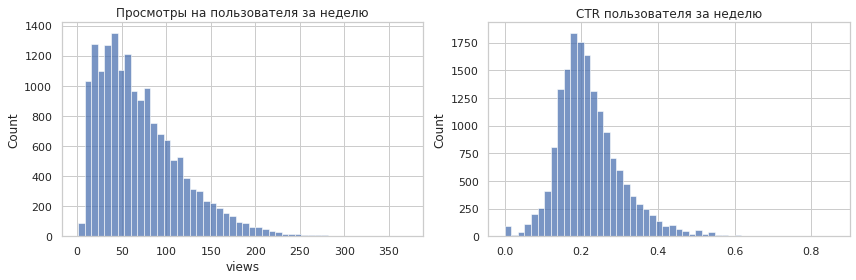

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_pre.views, bins=50, ax=axes[0])
axes[0].set_title("Просмотры на пользователя за неделю")
sns.histplot(df_pre.likes / df_pre.views, bins=50, ax=axes[1])
axes[1].set_title("CTR пользователя за неделю")
plt.tight_layout()
plt.savefig("../images/pre_period_distributions.png", dpi=120)
plt.show()

Распределение просмотров сильно скошено вправо: небольшая доля активных пользователей даёт большую часть показов. Это ещё один довод в пользу глобального CTR, взвешенного по просмотрам.

## 3. MDE по формуле

Для линеаризованной метрики:

$$MDE_{abs} = \frac{(z_{1-\alpha/2} + z_{1-\beta}) \cdot \sigma_L \cdot \sqrt{2/n}}{\overline{views}}$$

In [6]:
mde = ab.mde_ctr(df_pre.likes, df_pre.views, n)
pd.Series(mde)

ctr        0.211240
abs_mde    0.003154
rel_mde    0.014931
dtype: float64

In [7]:
pd.DataFrame({
    "rel_mde": [0.01, 0.02, 0.03, 0.05],
}).assign(n_per_group=lambda x: x.rel_mde.apply(lambda m: ab.sample_size_ctr(df_pre.likes, df_pre.views, m)))

,rel_mde,n_per_group
0,0.01,18642
1,0.02,4661
2,0.03,2072
3,0.05,746


При фактическом размере групп тест способен заметить относительное изменение глобального CTR не меньше `rel_mde` из таблицы выше. Меньшие эффекты за неделю надёжно не обнаружить.

## 4. Проверка мощности симуляцией

Формула опирается на нормальное приближение. Проверим её симуляцией: много раз набираем две группы бутстрапом из реальных пользователей предпериода (просмотры и лайки пользователя берутся вместе), в тестовой группе добавляем лайки так, чтобы CTR вырос на заданный процент, и считаем долю значимых результатов.

В исходной версии лайки генерировались биномиально поверх уже наблюдённого CTR пользователя. Так случайный шум учитывался дважды, и мощность получалась заниженной.

In [8]:
uplifts = np.round(np.arange(0, 0.061, 0.01), 3)

curve = ab.power_curve(df_pre, n, uplifts, n_iter=500, seed=42)
curve

,rel_uplift,power
0,0.00,0.054
1,0.01,0.474
2,0.02,0.952
3,0.03,1.000
4,0.04,1.000
5,0.05,1.000
6,0.06,1.000


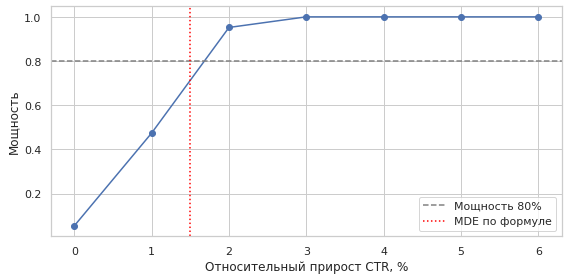

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve.rel_uplift * 100, curve.power, marker="o")
ax.axhline(ab.POWER, color="grey", linestyle="--", label="Мощность 80%")
ax.axvline(mde["rel_mde"] * 100, color="red", linestyle=":", label="MDE по формуле")
ax.set_xlabel("Относительный прирост CTR, %")
ax.set_ylabel("Мощность")
ax.legend()
plt.tight_layout()
plt.savefig("../images/power_curve.png", dpi=120)
plt.show()

При нулевом приросте доля значимых результатов должна быть около 5% — это проверка, что тест не завышает ошибку первого рода. Точка, где кривая пересекает 80%, должна быть близка к MDE по формуле.

## 5. Дополнительно: сценарий учебного задания

В исходной версии проекта мощность считалась для другого сценария: алгоритм добавляет 1–2 просмотра 90% пользователей с 30+ просмотрами, метрика — число лайков у этих пользователей. Тогда размер группы брался как половина всех пользователей ленты (30 591), хотя в эксперименте участвуют только группы 1 и 2, и мощность получилась около 0.65.

Здесь тот же сценарий пересчитан для реального размера групп. Он не используется для решения, потому что его метрика не совпадает с основной.

In [10]:
power_views = ab.simulate_power(
    df_pre, n,
    ab.add_views_heavy_users(threshold=30, share=0.9),
    n_iter=1000, metric="likes", min_views=30, seed=42,
)
power_views

0.427

## 6. Итог дизайна

In [11]:
design_summary = pd.Series({
    "Основная метрика": "global CTR = sum(likes) / sum(views)",
    "Тест": "t-тест на линеаризованных лайках + пуассоновский бутстрап",
    "alpha": ab.ALPHA,
    "Мощность": ab.POWER,
    "Пользователей в группе": n,
    "MDE, абс.": round(mde["abs_mde"], 4),
    "MDE, отн.": f"{mde['rel_mde']:.1%}",
    "Длительность": "7 дней",
})
design_summary

Основная метрика                       global CTR = sum(likes) / sum(views)
Тест                      t-тест на линеаризованных лайках + пуассоновск...
alpha                                                                  0.05
Мощность                                                                0.8
Пользователей в группе                                                 8362
MDE, абс.                                                            0.0032
MDE, отн.                                                              1.5%
Длительность                                                         7 дней
dtype: object

Эти параметры фиксируются до анализа. В `02_ab_test_analysis.ipynb` используется та же метрика и тот же α, а наблюдаемый эффект сравнивается с MDE.